In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB

from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('/kaggle/input/datasets/taruntiwarihp/phishing-site-urls/phishing_site_urls.csv')
df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [3]:
df['Label'].value_counts()

Label
good    392924
bad     156422
Name: count, dtype: int64

In [4]:
df.drop_duplicates(inplace=True)

In [5]:
df.isna().sum()

URL      0
Label    0
dtype: int64

In [6]:
df['Label'] = df['Label'].map({'good': 0, 'bad': 1})

In [7]:
X = df['URL']
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [8]:
vectorizer = TfidfVectorizer(
    token_pattern=r'[A-Za-z0-9]+',
    ngram_range=(1, 2),
    max_features=50000
)

In [9]:
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [10]:
multinml = MultinomialNB()

In [11]:
multinml.fit(X_train_vec, y_train)

MultinomialNB()

accuracy score:  95.99 %

Classification report
               precision    recall  f1-score   support

           0       0.96      0.99      0.97     78580
           1       0.96      0.86      0.91     22860

    accuracy                           0.96    101440
   macro avg       0.96      0.92      0.94    101440
weighted avg       0.96      0.96      0.96    101440



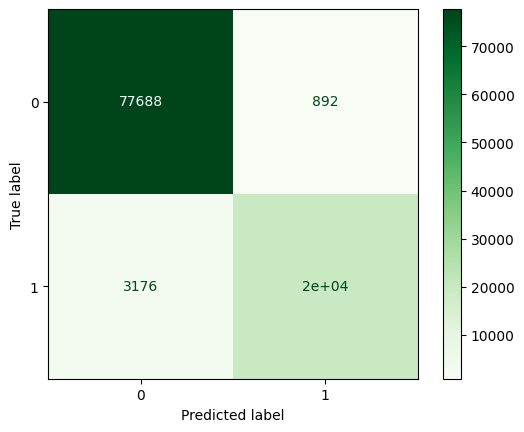

In [12]:
y_pred1 = multinml.predict(X_test_vec)

print('accuracy score: ', round(accuracy_score(y_test, y_pred1) * 100, 2), '%')
print('\nClassification report\n', classification_report(y_test, y_pred1))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred1,
    cmap='Greens'
)
plt.show()

In [13]:
complementNB = ComplementNB()

In [14]:
complementNB.fit(X_train_vec, y_train)

ComplementNB()

accuracy score:  94.95 %

Classification report
               precision    recall  f1-score   support

           0       0.97      0.96      0.97     78580
           1       0.87      0.91      0.89     22860

    accuracy                           0.95    101440
   macro avg       0.92      0.94      0.93    101440
weighted avg       0.95      0.95      0.95    101440



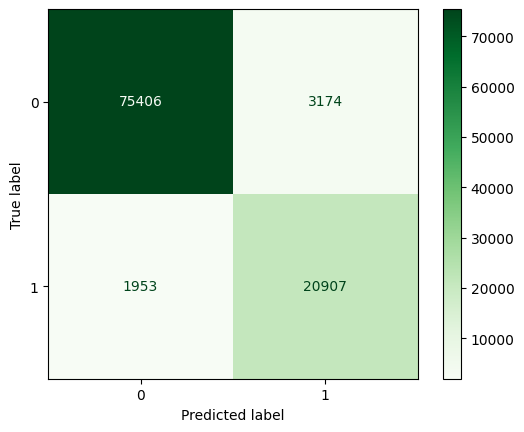

In [15]:
y_pred2 = complementNB.predict(X_test_vec)

print('accuracy score: ', round(accuracy_score(y_test, y_pred2) * 100, 2), '%')
print('\nClassification report\n', classification_report(y_test, y_pred2))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred2,
    cmap='Greens'
)
plt.show()

In [16]:
bernoulli = BernoulliNB()

In [17]:
bernoulli.fit(X_train_vec, y_train)

BernoulliNB()

accuracy score:  95.17 %

Classification report
               precision    recall  f1-score   support

           0       0.95      0.99      0.97     78580
           1       0.97      0.81      0.88     22860

    accuracy                           0.95    101440
   macro avg       0.96      0.90      0.93    101440
weighted avg       0.95      0.95      0.95    101440



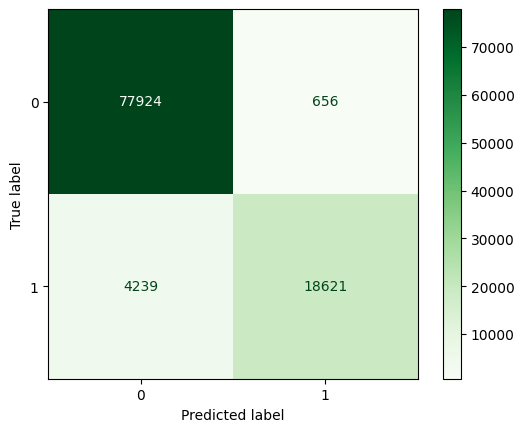

In [18]:
y_pred3 = bernoulli.predict(X_test_vec)

print('accuracy score: ', round(accuracy_score(y_test, y_pred3) * 100, 2), '%')
print('\nClassification report\n', classification_report(y_test, y_pred3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred3,
    cmap='Greens'
)
plt.show()

In [19]:
char_vec = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    max_features=150000
)

X_train_char = char_vec.fit_transform(X_train)
X_test_char = char_vec.transform(X_test)

In [21]:
best_alpha, best_f1 = 1.0, 0.0
pos_lbl = 'bad' if 'bad' in set(y_test) else 1
for alpha in [0.01, 0.05, 0.1, 0.2, 0.5]:
    nb = MultinomialNB(alpha=alpha)
    nb.fit(X_train_char, y_train)
    preds = nb.predict(X_test_char)
    f1 = f1_score(y_test, preds, pos_label=pos_lbl)
    acc = accuracy_score(y_test, preds)
    print(f"alpha={alpha:<4} | Accuracy: {acc*100:.2f}% | Bad F1-Score: {f1:.4f}")
    if f1 > best_f1:
        best_f1, best_alpha = f1, alpha

alpha=0.01 | Accuracy: 96.22% | Bad F1-Score: 0.9140
alpha=0.05 | Accuracy: 96.19% | Bad F1-Score: 0.9134
alpha=0.1  | Accuracy: 96.18% | Bad F1-Score: 0.9131
alpha=0.2  | Accuracy: 96.16% | Bad F1-Score: 0.9127
alpha=0.5  | Accuracy: 96.09% | Bad F1-Score: 0.9110



🏆 FINAL TUNED MultinomialNB (alpha=0.01, threshold=0.4)
Accuracy: 96.21%
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     78580
           1       0.93      0.90      0.91     22860

    accuracy                           0.96    101440
   macro avg       0.95      0.94      0.95    101440
weighted avg       0.96      0.96      0.96    101440



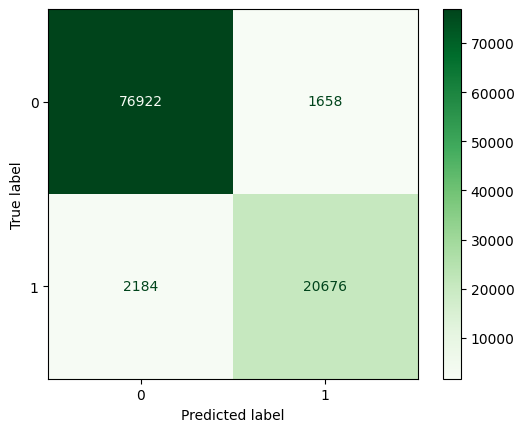

In [22]:
final_nb = MultinomialNB(alpha=best_alpha)
final_nb.fit(X_train_char, y_train)

bad_idx = list(final_nb.classes_).index(pos_lbl)
bad_probs = final_nb.predict_proba(X_test_char)[:, bad_idx]

best_thresh, max_f1 = 0.5, best_f1
for t in np.arange(0.30, 0.70, 0.05):
    t_preds = np.where(bad_probs >= t, pos_lbl, 'good' if pos_lbl == 'bad' else 0)
    f1 = f1_score(y_test, t_preds, pos_label=pos_lbl)
    if f1 > max_f1:
        max_f1, best_thresh = f1, round(float(t), 2)

final_preds = np.where(bad_probs >= best_thresh, pos_lbl, 'good' if pos_lbl == 'bad' else 0)
print(f"\n🏆 FINAL TUNED MultinomialNB (alpha={best_alpha}, threshold={best_thresh})")
print(f"Accuracy: {accuracy_score(y_test, final_preds)*100:.2f}%")
print(classification_report(y_test, final_preds))
ConfusionMatrixDisplay.from_predictions(y_test, final_preds, cmap='Greens')
plt.show()

In [23]:
import joblib

bundle = {
    "vectorizer": char_vec,
    "model": final_nb,
    "threshold": best_thresh
}

joblib.dump(bundle, "phising_url_model.joblib", compress=3)

print("Saved successfully! Threshold:", best_thresh)

Saved successfully! Threshold: 0.4
